# Reproducing GRIN on AQI-36

This notebook runs the AQI-36 out-of-sample experiment with the authors' GRIN model. It downloads the data and model code, trains GRIN and compares its test error with the paper and two simple baselines.

The CPU run uses **30 epochs, 512 windows per epoch and one seed**. The paper uses up to 300 epochs and 5,120 windows per epoch, repeated over five runs.

**Test MAE was 12.789 µg/m³**, compared with **12.08 ± 0.47** in the paper. Training took **13.3 minutes** for **480 updates**. Epoch **18** had the lowest validation error.

Sources: [paper](https://arxiv.org/abs/2108.00298v3), [original code at the fixed commit](https://github.com/Graph-Machine-Learning-Group/grin/tree/4a28afbb092600b6e6abeeabaaf67e87dbd1ed6e), [processed data](https://huggingface.co/datasets/TorchSpatiotemporal/ProcessedDatasets/tree/v1.0.0/air).

Code and instructions for running this experiment: [GitHub repository](https://github.com/Achiee7/DW-Assignement-2--Implementing-GRIN-for-imputation).

## 1 Setup and parameters

Use Python 3.12 and follow the installation commands in the README. Open this notebook from the project root or its `notebooks` folder. It checks and loads an existing run when the settings and file hashes match. If no result is available, it trains the model. Set `RETRAIN = True` to train again.

In [1]:
from pathlib import Path
from dataclasses import asdict
import json, sys
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'src' / 'grin_reproduction').exists(), 'Open from the cloned project.'
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
from grin_reproduction.data import prepare_aqi36, _covered
from grin_reproduction.experiment import Config, run_experiment, load_run
from grin_reproduction.upstream import COMMIT
plt.rcParams.update({'figure.figsize': (10, 3.6), 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .18})
RETRAIN = False
PROFILE = 'bounded'  # 'paper' runs one seed with the published budget
CONFIG = Config(seed=42, max_epochs=30, samples_per_epoch=512) if PROFILE == 'bounded' else Config.paper(seed=42)
OUTPUT = ROOT / 'results' / f'{CONFIG.profile}_seed_{CONFIG.seed}'
FIGURES = OUTPUT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
display(pd.DataFrame(asdict(CONFIG).items(), columns=['Parameter','Value']))
print(f'Python {sys.version.split()[0]}, PyTorch {torch.__version__}, device {CONFIG.device}')

,Parameter,Value
0,profile,bounded
1,seed,42
2,max_epochs,30
3,samples_per_epoch,512
4,batch_size,32
5,patience,40
6,learning_rate,0.001
7,min_learning_rate,0.0001
8,whiten_probability,0.05
9,gradient_clip,5.0


Python 3.12.14, PyTorch 2.14.1+cpu, device cpu


## 2 Prepare the data

AQI-36 contains hourly PM2.5 readings from 36 stations. The released file has 8,759 rows, starting at 01:00 on 1 May 2014. Its original evaluation mask is used here. The 25% random mask used in the paper's traffic experiments does not apply to AQI-36.

March, June, September and December are test months. Validation windows are placed before these months, and overlapping training windows are removed. The mean and standard deviation are calculated from visible training readings only. The graph connects stations using a thresholded Gaussian kernel of their distances. Naturally missing readings are excluded from training and evaluation.

In [2]:
data = prepare_aqi36(ROOT / 'data' / 'raw')
summary = {'Matrix': str(data.values.shape), 'First timestamp': str(data.timestamps[0]),
 'Last timestamp': str(data.timestamps[-1]), 'Original missing': int((~data.observed_mask).sum()),
 'Fixed targets across all dates': int(data.eval_mask.sum()), 'Training windows': len(data.train_starts),
 'Validation windows': len(data.val_starts), 'Test windows': len(data.test_starts),
 'Directed graph entries': int((data.adjacency > 0).sum()), 'Training mean': data.mean, 'Training std': data.std}
display(pd.DataFrame(summary.items(), columns=['Data property','Value']))
print('Data archive SHA256:', data.provenance['archive_sha256'])
print('Original source commit:', COMMIT)

,Data property,Value
0,Matrix,"(8759, 36)"
1,First timestamp,2014-05-01 01:00:00
2,Last timestamp,2015-04-30 23:00:00
3,Original missing,41771
4,Fixed targets across all dates,35737
5,Training windows,4948
6,Validation windows,564
7,Test windows,2788
8,Directed graph entries,654
9,Training mean,90.636375


Data archive SHA256: 95d3c5cab14fc007f43c57b745a93e5f88201cbb92a755644ca9777848343317
Original source commit: 4a28afbb092600b6e6abeeabaaf67e87dbd1ed6e


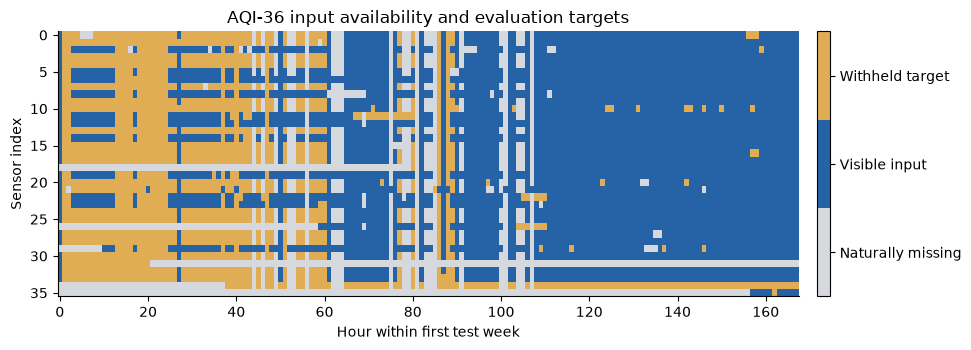

In [3]:
from matplotlib.colors import ListedColormap
start = int(data.test_starts[0]); span = slice(start, start + 168)
state = np.where(~data.observed_mask[span], 0, np.where(data.eval_mask[span], 2, 1))
fig, ax = plt.subplots()
im = ax.imshow(state.T, aspect='auto', interpolation='nearest', vmin=-.5, vmax=2.5,
 cmap=ListedColormap(['#d5d8dc','#2563a6','#e0ad54']))
ax.grid(False)
ax.set(xlabel='Hour within first test week', ylabel='Sensor index', title='AQI-36 input availability and evaluation targets')
cb = fig.colorbar(im, ax=ax, ticks=[0,1,2], pad=.02)
cb.ax.set_yticklabels(['Naturally missing','Visible input','Withheld target'])
fig.tight_layout(); fig.savefig(FIGURES / 'missingness.png', dpi=180); plt.show()

## 3 Train GRIN

The loader downloads the authors' model at a fixed commit and checks its files using SHA-256. A PyTorch training loop replaces the original Lightning setup. The model code is unchanged.

Each 36-hour window is processed forwards and backwards. Training hides an additional 5% of visible inputs. The loss sums five masked MAEs: the final output and the two imputation stages in each direction. All five terms are scored on the readings that were visible before this extra masking. The hidden state has 64 dimensions and the node embedding has 8. The graph operations and optimiser settings follow the authors' configuration.

The checkpoint with the lowest validation window MAE is kept. After training, predictions from overlapping test windows are averaged for each timestamp before the test error is calculated.

In [4]:
if (OUTPUT / 'metrics.json').exists() and not RETRAIN:
    metrics = load_run(data, CONFIG, OUTPUT)
    print('Loaded validated results. Set RETRAIN=True to train again.')
else:
    if RETRAIN and (OUTPUT / 'metrics.json').exists():
        from datetime import datetime
        OUTPUT = ROOT / 'results' / f'{CONFIG.profile}_seed_{CONFIG.seed}_{datetime.now():%Y%m%d_%H%M%S}'
        FIGURES = OUTPUT / 'figures'; FIGURES.mkdir(parents=True, exist_ok=True)
    metrics = run_experiment(data, CONFIG, OUTPUT)
print(f"Best epoch {metrics['best_epoch']}; {metrics['optimizer_updates']} updates; {metrics['elapsed_seconds']/60:.1f} minutes")

Epoch   1: loss=2.6002, val MAE=22.237, 39.2s


Epoch   2: loss=1.4247, val MAE=15.174, 27.7s


Epoch   3: loss=1.1061, val MAE=14.640, 25.5s


Epoch   4: loss=1.0333, val MAE=13.277, 25.2s


Epoch   5: loss=0.9201, val MAE=12.064, 24.7s


...

Epoch  28: loss=0.6503, val MAE=10.485, 25.6s


Epoch  29: loss=0.6534, val MAE=10.482, 25.7s


Epoch  30: loss=0.6472, val MAE=10.523, 25.6s


{
  "mae": 12.78933242604614,
  "mse": 501.3931947911062,
  "rmse": 22.3918108868199,
  "mre": 0.18358650012562386,
  "window_mae": 13.274202774258287,
  "n_targets": 20434,
  "n_windows": 2788,
  "best_epoch": 18,
  "best_validation_window_mae": 10.221093735551209,
  "elapsed_seconds": 800.7982526998967,
  "epochs_completed": 30,
  "optimizer_updates": 480,
  "parameter_count": 191079,
  "seed": 42,
  "profile": "bounded",
  "published_grin_mae": 12.08,
  "published_grin_mae_std": 0.47,
  "difference_from_published_mae": 0.7093324260461404,
  "baselines": {
    "Training station mean": {
      "mae": 55.1844482421875,
      "mse": 4721.5498046875,
      "n_targets": 20434
    },
    "Linear interpolation": {
      "mae": 14.598261833190918,
      "mse": 691.1583862304688,
      "n_targets": 20434
    }
  }
}


Best epoch 18; 480 updates; 13.3 minutes


## 4 Compare the results

The validation curve below determines which checkpoint is kept. Test error is not used for this decision. The paper's standard deviations describe five runs; only one seed was tested here.

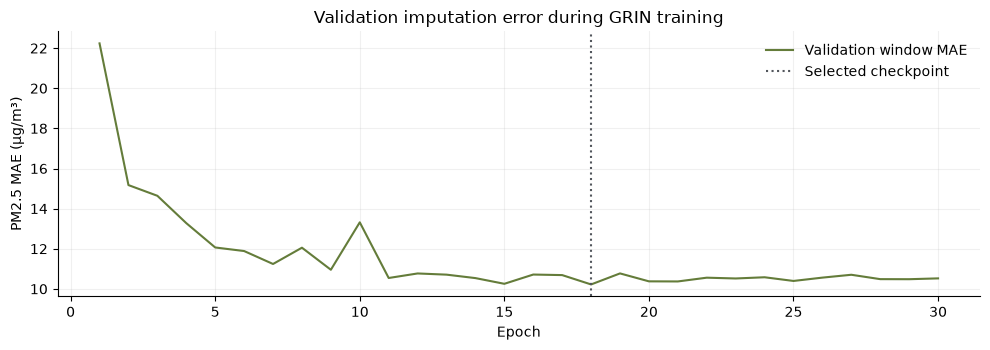

In [5]:
history = pd.read_json(OUTPUT / 'history.json')
fig, ax = plt.subplots()
ax.plot(history.epoch, history.val_window_mae, color='#647c3a', label='Validation window MAE')
ax.axvline(metrics['best_epoch'], color='#52565c', linestyle=':', label='Selected checkpoint')
ax.set(xlabel='Epoch', ylabel='PM2.5 MAE (µg/m³)', title='Validation imputation error during GRIN training')
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIGURES / 'validation.png', dpi=180); plt.show()

In [6]:
rows = [{'Method':'GRIN local','Evaluation':'Measured single seed','MAE':metrics['mae'],'MSE':metrics['mse']}]
for name, result in metrics['baselines'].items():
    rows.append({'Method':name,'Evaluation':'Measured control','MAE':result['mae'],'MSE':result['mse']})
rows += [{'Method':'GRIN paper','Evaluation':'Published five-run mean','MAE':12.08,'MSE':523.14},
         {'Method':'BRITS paper','Evaluation':'Published five-run mean','MAE':14.50,'MSE':662.36}]
comparison = pd.DataFrame(rows)
display(comparison.style.format({'MAE':'{:.3f}','MSE':'{:.2f}'}))
comparison.to_csv(OUTPUT / 'comparison.csv', index=False)
print(f"Targets: {metrics['n_targets']:,}; windows: {metrics['n_windows']:,}; MRE: {100*metrics['mre']:.2f}%")
print(f"Difference from published MAE: {metrics['mae']-12.08:+.3f} µg/m³ ({100*(metrics['mae']/12.08-1):+.1f}%)")

,Method,Evaluation,MAE,MSE
0,GRIN local,Measured single seed,12.789,501.39
1,Training station mean,Measured control,55.184,4721.55
2,Linear interpolation,Measured control,14.598,691.16
3,GRIN paper,Published five-run mean,12.080,523.14
4,BRITS paper,Published five-run mean,14.500,662.36


Targets: 20,434; windows: 2,788; MRE: 18.36%
Difference from published MAE: +0.709 µg/m³ (+5.9%)


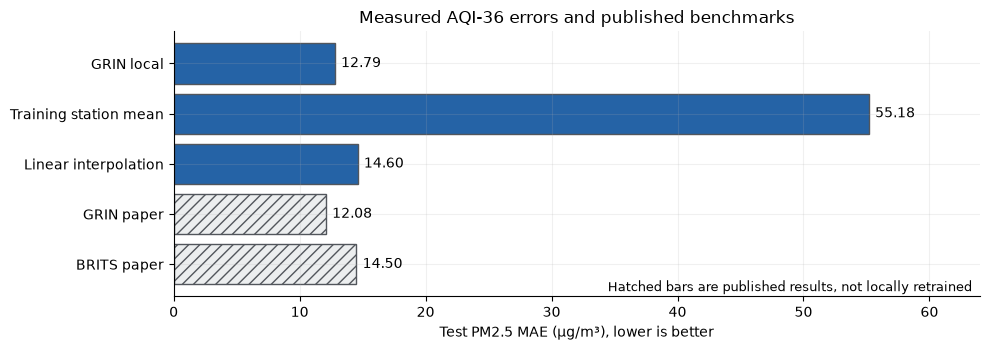

In [7]:
fig, ax = plt.subplots()
for i, row in comparison.iterrows():
    pub = row.Evaluation.startswith('Published')
    ax.barh(i, row.MAE, color='#eceeef' if pub else '#2563a6', edgecolor='#52565c', hatch='///' if pub else None)
    ax.text(row.MAE+.5, i, f'{row.MAE:.2f}', va='center')
ax.set_yticks(range(len(comparison)), comparison.Method); ax.invert_yaxis()
ax.set(xlabel='Test PM2.5 MAE (µg/m³), lower is better', title='Measured AQI-36 errors and published benchmarks', xlim=(0, comparison.MAE.max()*1.16))
ax.text(.99,.02,'Hatched bars are published results, not locally retrained',transform=ax.transAxes,ha='right',fontsize=9)
fig.tight_layout(); fig.savefig(FIGURES / 'mae_comparison.png',dpi=180);plt.show()

## 5 Look at one sensor

The sensor below has the most withheld readings during the first test week. It was chosen without checking prediction errors. Orange crosses show predictions for withheld readings. Blue points, where present, show readings that were visible to GRIN. The grey line shows the available ground truth.

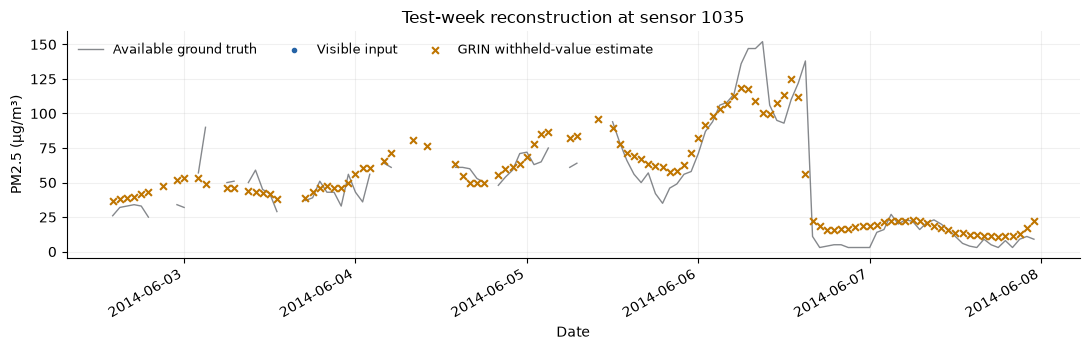

In [8]:
saved = np.load(OUTPUT / 'test_predictions.npz'); prediction = saved['prediction']
start = int(data.test_starts[0]); stop = start+168
node = int(data.eval_mask[start:stop].sum(axis=0).argmax())
times = data.timestamps[start:stop]; truth = data.raw_values[start:stop,node]
held = data.eval_mask[start:stop,node] & np.isfinite(prediction[start:stop,node])
visible = data.input_mask[start:stop,node]
fig, ax = plt.subplots(figsize=(11,3.6))
ax.plot(times,truth,color='#52565c',lw=1,alpha=.7,label='Available ground truth')
ax.scatter(times[visible],truth[visible],color='#2563a6',s=9,label='Visible input',zorder=3)
ax.scatter(times[held],prediction[start:stop,node][held],color='#bf7500',marker='x',s=24,label='GRIN withheld-value estimate',zorder=4)
ax.set(xlabel='Date',ylabel='PM2.5 (µg/m³)',title=f'Test-week reconstruction at sensor {data.stations.index[node]}')
ax.legend(frameon=False,ncol=3,fontsize=9);fig.autofmt_xdate();fig.tight_layout()
fig.savefig(FIGURES / 'sensor_reconstruction.png',dpi=180);plt.show()

## 6 Checks and discussion

This run uses less training, a shorter learning-rate schedule and newer software than the paper. It also uses one seed; the authors' original seeds were not published. These differences may affect the results, but further runs would be needed to measure their individual effects. The local mean and interpolation baselines use the same test readings as GRIN and were implemented separately from the paper's baseline code.

Run `python -m pytest` for the masking and model tests. To use the paper's training budget, select `PROFILE = 'paper'`. Repeat with five seeds to estimate variation between runs.

In [9]:
train = _covered(data.train_starts,data.window,len(data.values))
val = _covered(data.val_starts,data.window,len(data.values))
test = _covered(data.test_starts,data.window,len(data.values))
assert not (train & val).any() and not (train & test).any() and not (val & test).any()
assert not (data.input_mask[test] & data.eval_mask[test]).any()
assert np.isfinite(prediction[test]).all()
visible_test = data.input_mask & test[:,None]
assert np.allclose(prediction[visible_test],data.values[visible_test],atol=1e-4)
assert load_run(data,CONFIG,OUTPUT)['mae'] == metrics['mae']
print('Passed temporal separation, hidden targets, finite predictions, visible-value preservation and artifact integrity.')
display(Markdown(f"**Measured GRIN MAE: {metrics['mae']:.3f} µg/m³**, versus published **12.08 ± 0.47**. "
 f"This run used **{metrics['optimizer_updates']:,} updates** and one seed; a paper-budget seed permits up to 48,000 updates."))

Passed temporal separation, hidden targets, finite predictions, visible-value preservation and artifact integrity.


**Measured GRIN MAE: 12.789 µg/m³**, versus published **12.08 ± 0.47**. This run used **480 updates** and one seed; a paper-budget seed permits up to 48,000 updates.